In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv("data/car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
df.describe().round()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.0,10000.0,10000.0,10000.0,9123.0,10000.0,9736.0,10000.0
mean,2000.0,4.0,2269.0,6.0,254.0,4287.0,19.0,30.0
std,14.0,1.0,183.0,1.0,23.0,266.0,1.0,3.0
min,1975.0,2.0,1590.0,4.0,171.0,3320.0,14.0,20.0
25%,1987.0,3.0,2150.0,6.0,239.0,4110.0,18.0,28.0
50%,2000.0,4.0,2270.0,6.0,254.0,4280.0,19.0,30.0
75%,2012.0,4.0,2390.0,6.0,270.0,4470.0,20.0,32.0
max,2024.0,5.0,3110.0,8.0,334.0,5460.0,24.0,41.0


In [4]:
for c in ["acceleration","horsepower"]:
    df[c] = df[c].replace(to_replace = np.nan, value = 0.0)


In [5]:
df_full_train , df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train , df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values
y_test = df_test["fuel_efficiency_mpg"].values

In [6]:
del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

In [7]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_val)
y_pred

array([28.61358616, 28.61358616, 28.61358616, ..., 31.16766139,
       28.61358616, 28.61358616], shape=(2000,))

In [8]:
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [11]:
from sklearn.metrics import root_mean_squared_error

rf = RandomForestRegressor(n_estimators=10, random_state=1,n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_val)
rmse = np.sqrt(np.mean((y_val - y_pred_rf) ** 2))

rmse

np.float64(1.8332197358745623)

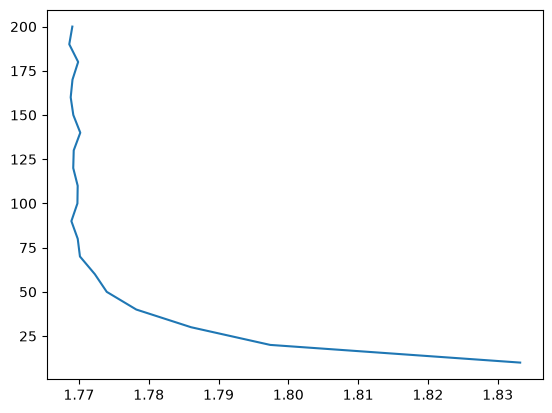

In [12]:
n_est_list=[]
rmse_score_list=[]

for i in range(10,201,10):
    n_est_list.append(i)

    rf = RandomForestRegressor(n_estimators=i, random_state=1,n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred_rf = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred_rf)
    rmse_score_list.append(rmse)
plt.plot(rmse_score_list,n_est_list)

rmse stops improving around 80-100

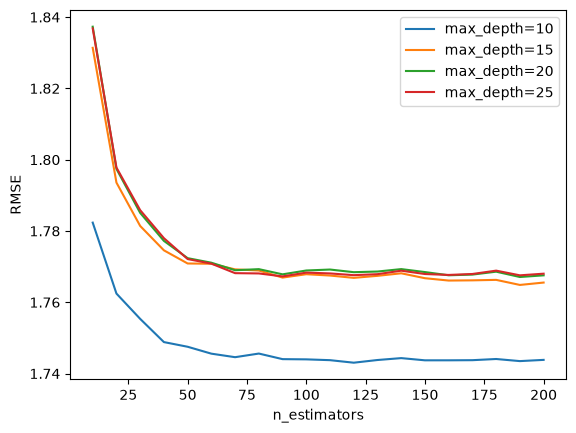

In [13]:
for max_depth in [10, 15, 20, 25]:
    scores = []

    for n_estimators in range(10, 201, 10):
        rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=1,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)

        prediction = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, prediction)
        scores.append(rmse)

    plt.plot(range(10, 201, 10), scores, label=f"max_depth={max_depth}")

plt.xlabel("n_estimators")
plt.ylabel("RMSE")
plt.legend()
plt.show()

best max_depth = 10

In [14]:
rf_gain = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1,n_jobs=-1)
rf_gain.fit(X_train, y_train)

importances = rf_gain.feature_importances_
feature_names = dv.get_feature_names_out()

df_importances = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)

df_importances

,feature,importance
9,model_year,0.296107
15,vehicle_weight,0.203313
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078271
4,engine_displacement,0.061281
0,acceleration,0.054998
14,origin=USA,0.042152
2,drivetrain=Front-wheel drive,0.020062
11,num_doors,0.019401
5,fuel_type=Diesel,0.016571


vehicle_weight most important among options

In [15]:
import xgboost as xgb

In [18]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100)

y_pred = model.predict(dval)
rmse = root_mean_squared_error(y_val, y_pred)

print("eta=0.3",rmse)

eta=0.3 1.8264579799904583


In [20]:
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6, 
    'min_child_weight': 1, 
    'objective': 'reg:squarederror', 
    'nthread': 8, 
    'seed': 1, 
    'verbosity': 1,
    'eval_metric': 'rmse'  # Tracks RMSE during training
}

# Define the watchlist
watchlist = [(dtrain, 'train'), (dval, 'val')]

# Train the model with the watchlist
model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=100,
    evals=watchlist
)

y_pred = model.predict(dval)
rmse = root_mean_squared_error(y_val, y_pred)
print("eta=0.1", rmse)


[0]	train-rmse:2.74739	val-rmse:2.78635
[1]	train-rmse:2.58527	val-rmse:2.63162
[2]	train-rmse:2.44540	val-rmse:2.50036
[3]	train-rmse:2.32187	val-rmse:2.38568
[4]	train-rmse:2.21445	val-rmse:2.28765
[5]	train-rmse:2.12109	val-rmse:2.20428
[6]	train-rmse:2.03996	val-rmse:2.13241
[7]	train-rmse:1.96795	val-rmse:2.06798
[8]	train-rmse:1.90640	val-rmse:2.01618
[9]	train-rmse:1.85240	val-rmse:1.96998
[10]	train-rmse:1.80592	val-rmse:1.93152
[11]	train-rmse:1.76410	val-rmse:1.89688
[12]	train-rmse:1.72781	val-rmse:1.86726
[13]	train-rmse:1.69564	val-rmse:1.84312
[14]	train-rmse:1.66745	val-rmse:1.82218
[15]	train-rmse:1.64286	val-rmse:1.80346
[16]	train-rmse:1.62187	val-rmse:1.79038
[17]	train-rmse:1.60321	val-rmse:1.77726
[18]	train-rmse:1.58694	val-rmse:1.76827
[19]	train-rmse:1.57240	val-rmse:1.75951
[20]	train-rmse:1.55847	val-rmse:1.75076
[21]	train-rmse:1.54640	val-rmse:1.74347
[22]	train-rmse:1.53643	val-rmse:1.73912
[23]	train-rmse:1.52675	val-rmse:1.73485
[24]	train-rmse:1.51763	va

eta = 0.1 has lower rmse
